# Cognifyz Technologies - Data Science Internship
## Level 2 | Task 1: Table Booking & Online Delivery | Task 2: Price Range Analysis | Task 3: Feature Engineering
Dataset: `Dataset_.csv` (restaurant data)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

# Dataset_.csv must be in the same folder as this notebook
df = pd.read_csv("Dataset .csv", encoding="latin-1")
df.columns = df.columns.str.replace("ï»¿", "", regex=False).str.strip()  # remove BOM from first column name
df.head()

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [2]:
df["Cuisines"] = df["Cuisines"].fillna("Unknown")   # only 9 missing values (from Level 1 preprocessing)
df.shape

(9551, 21)

# Task 1: Table Booking and Online Delivery
### 1.1 Percentage of restaurants offering table booking and online delivery

Table booking (%):
 Has Table booking
No     87.88
Yes    12.12
Name: proportion, dtype: float64 

Online delivery (%):
 Has Online delivery
No     74.34
Yes    25.66
Name: proportion, dtype: float64


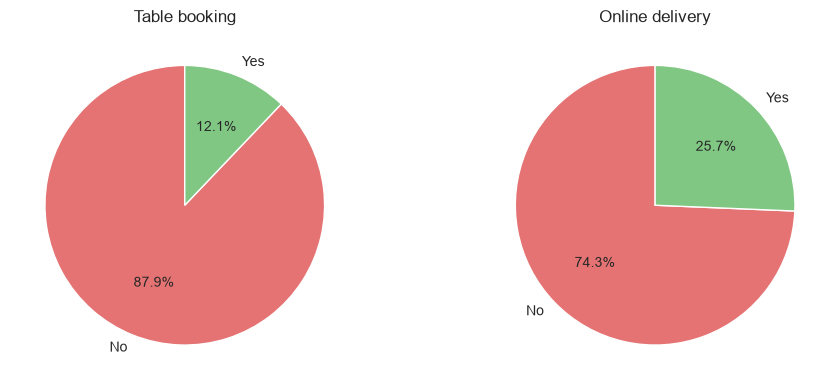

In [3]:
tb = df["Has Table booking"].value_counts(normalize=True).mul(100).round(2)
od = df["Has Online delivery"].value_counts(normalize=True).mul(100).round(2)
print("Table booking (%):\n", tb, "\n\nOnline delivery (%):\n", od)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].pie(tb, labels=tb.index, autopct="%1.1f%%", colors=["#e57373", "#81c784"], startangle=90)
ax[0].set_title("Table booking")
ax[1].pie(od, labels=od.index, autopct="%1.1f%%", colors=["#e57373", "#81c784"], startangle=90)
ax[1].set_title("Online delivery")
plt.tight_layout(); plt.show()

### 1.2 Average rating: with vs without table booking

Has Table booking
No     2.559
Yes    3.442
Name: Aggregate rating, dtype: float64

Excluding unrated restaurants:
 Has Table booking
No     3.414
Yes    3.588
Name: Aggregate rating, dtype: float64


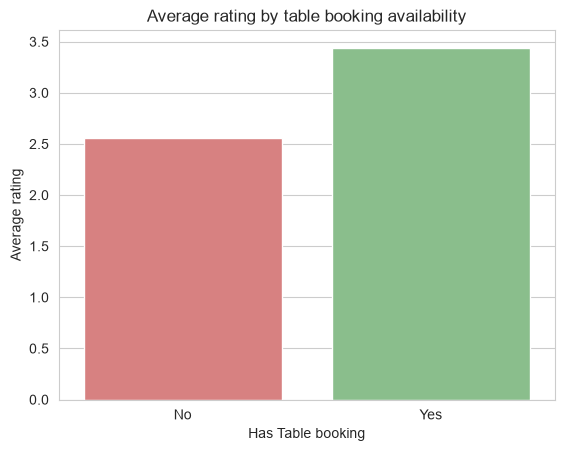

In [4]:
avg_tb = df.groupby("Has Table booking")["Aggregate rating"].mean().round(3)
print(avg_tb)

rated = df[df["Aggregate rating"] > 0]   # fair comparison excluding unrated (0) restaurants
print("\nExcluding unrated restaurants:\n", rated.groupby("Has Table booking")["Aggregate rating"].mean().round(3))

sns.barplot(x=avg_tb.index, y=avg_tb.values, palette=["#e57373", "#81c784"])
plt.title("Average rating by table booking availability"); plt.ylabel("Average rating"); plt.show()

### 1.3 Online delivery availability across price ranges

Has Online delivery     No    Yes
Price range                      
1                    84.23  15.77
2                    58.69  41.31
3                    70.81  29.19
4                    90.96   9.04


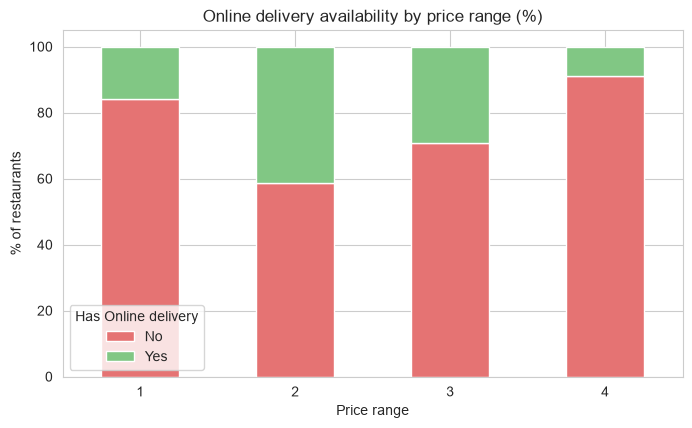

In [5]:
delivery_by_price = pd.crosstab(df["Price range"], df["Has Online delivery"], normalize="index").mul(100).round(2)
print(delivery_by_price)

delivery_by_price.plot(kind="bar", stacked=True, color=["#e57373", "#81c784"], figsize=(8, 4.5))
plt.title("Online delivery availability by price range (%)"); plt.ylabel("% of restaurants")
plt.xlabel("Price range"); plt.xticks(rotation=0); plt.show()

**Observation:** Only ~12% of restaurants offer table booking and ~26% offer online delivery. Restaurants **with table booking have clearly higher average ratings**. Online delivery is most common in price range 2 and drops off sharply for the most expensive (range 4) restaurants.

# Task 2: Price Range Analysis
### 2.1 Most common price range

Price range
1    4444
2    3113
3    1408
4     586
Name: count, dtype: int64

Most common price range: 1 (46.5% of restaurants)


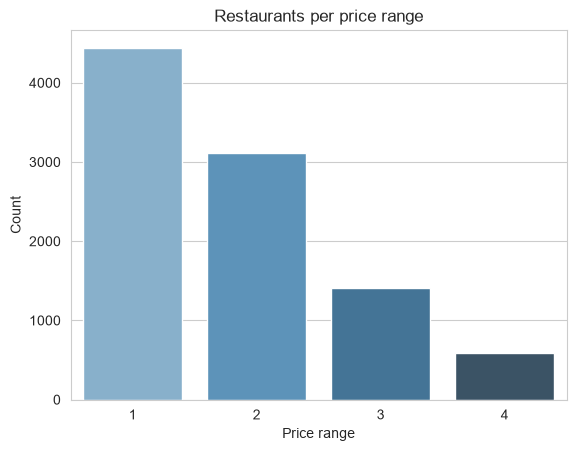

In [6]:
price_counts = df["Price range"].value_counts().sort_index()
print(price_counts)
print("\nMost common price range:", price_counts.idxmax(), f"({price_counts.max() / len(df) * 100:.1f}% of restaurants)")

sns.barplot(x=price_counts.index, y=price_counts.values, palette="Blues_d")
plt.title("Restaurants per price range"); plt.ylabel("Count"); plt.show()

### 2.2 Average rating for each price range

Price range
1    2.000
2    2.941
3    3.683
4    3.818
Name: Aggregate rating, dtype: float64


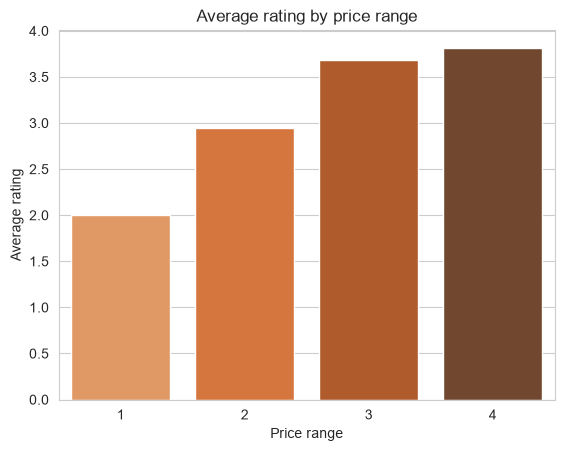

In [7]:
avg_price = df.groupby("Price range")["Aggregate rating"].mean().round(3)
print(avg_price)

sns.barplot(x=avg_price.index, y=avg_price.values, palette="Oranges_d")
plt.title("Average rating by price range"); plt.ylabel("Average rating"); plt.show()

### 2.3 Color representing the highest average rating

Rating color
Dark Green    4.660
Green         4.168
Yellow        3.683
Orange        3.052
Red           2.298
White         0.000
Name: Aggregate rating, dtype: float64

Color with highest average rating: Dark Green

Most frequent rating color in each price range:
     Price range Rating color  count
2             1       Orange   1898
8             2       Orange   1425
17            3       Yellow    498
23            4       Yellow    200


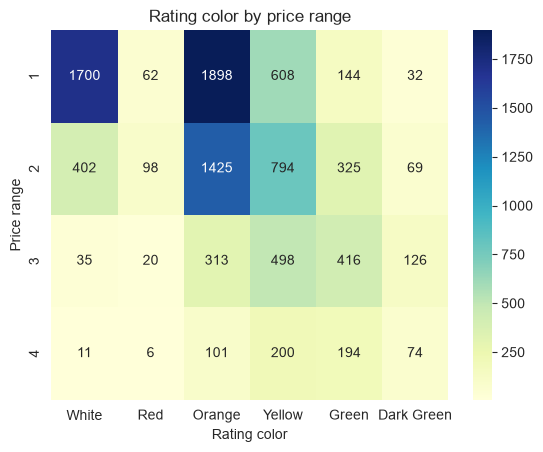

In [8]:
# Average rating per rating color
color_avg = df.groupby("Rating color")["Aggregate rating"].mean().sort_values(ascending=False).round(3)
print(color_avg)
print("\nColor with highest average rating:", color_avg.idxmax())

# Most common rating color inside each price range + the average rating of that color
dominant = (df.groupby(["Price range", "Rating color"]).size().reset_index(name="count")
              .sort_values(["Price range", "count"], ascending=[True, False]).groupby("Price range").head(1))
print("\nMost frequent rating color in each price range:\n", dominant)

# Rating color vs price range heatmap
ct = pd.crosstab(df["Price range"], df["Rating color"])
order = [c for c in ["White", "Red", "Orange", "Yellow", "Green", "Dark Green"] if c in ct.columns]
sns.heatmap(ct[order], annot=True, fmt="d", cmap="YlGnBu")
plt.title("Rating color by price range"); plt.show()

**Observation:** Average rating rises with price range (range 1 ≈ 2.0 → range 4 ≈ 3.8). The color with the highest average rating is **Dark Green** (~4.66, i.e. the *Excellent* class). Expensive price ranges contain a much larger share of Yellow/Green restaurants, while range 1 is dominated by White (unrated) and Orange.

# Task 3: Feature Engineering
### 3.1 Extract additional features (length of restaurant name / address)

In [9]:
fe = df.copy()
fe["Restaurant Name Length"] = fe["Restaurant Name"].str.len()
fe["Address Length"] = fe["Address"].str.len()
fe["Number of Cuisines"] = fe["Cuisines"].apply(lambda x: 0 if x == "Unknown" else len(x.split(",")))
fe[["Restaurant Name", "Restaurant Name Length", "Address", "Address Length", "Cuisines", "Number of Cuisines"]].head()

,Restaurant Name,Restaurant Name Length,Address,Address Length,Cuisines,Number of Cuisines
0,Le Petit Souffle,16,"Third Floor, Century City Mall, Kalayaan Avenu...",71,"French, Japanese, Desserts",3
1,Izakaya Kikufuji,16,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...",67,Japanese,1
2,Heat - Edsa Shangri-La,22,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...",56,"Seafood, Asian, Filipino, Indian",4
3,Ooma,4,"Third Floor, Mega Fashion Hall, SM Megamall, O...",70,"Japanese, Sushi",2
4,Sambo Kojin,11,"Third Floor, Mega Atrium, SM Megamall, Ortigas...",64,"Japanese, Korean",2


### 3.2 New binary features by encoding categorical variables

In [10]:
fe["Has Table Booking"] = (fe["Has Table booking"] == "Yes").astype(int)
fe["Has Online Delivery"] = (fe["Has Online delivery"] == "Yes").astype(int)
fe["Is Delivering Now"] = (fe["Is delivering now"] == "Yes").astype(int)
fe[["Has Table booking", "Has Table Booking", "Has Online delivery", "Has Online Delivery"]].head()

,Has Table booking,Has Table Booking,Has Online delivery,Has Online Delivery
0,Yes,1,No,0
1,Yes,1,No,0
2,Yes,1,No,0
3,No,0,No,0
4,Yes,1,No,0


### 3.3 Check the new features against the target

Number of Cuisines        0.248
Has Online Delivery       0.226
Has Table Booking         0.190
Is Delivering Now         0.019
Address Length            0.006
Restaurant Name Length   -0.031
Name: Aggregate rating, dtype: float64


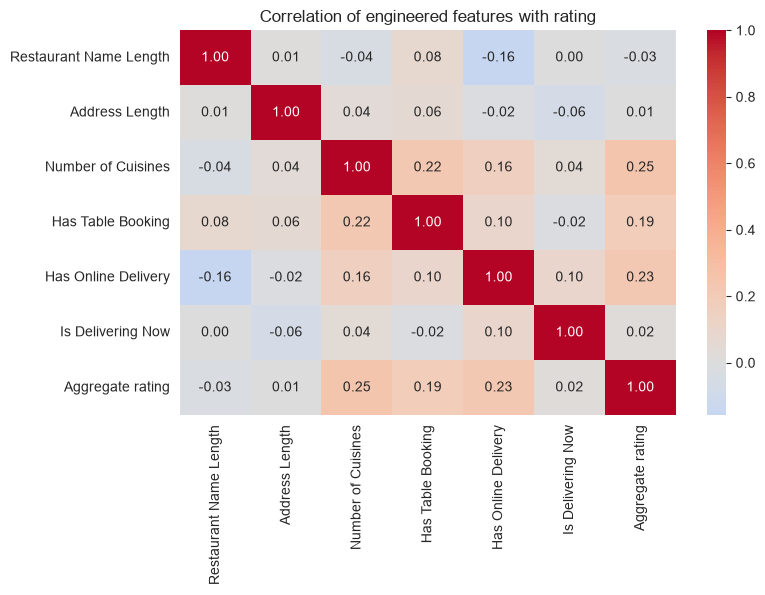

Saved Dataset_engineered.csv (9551, 27)


In [11]:
new_feats = ["Restaurant Name Length", "Address Length", "Number of Cuisines",
             "Has Table Booking", "Has Online Delivery", "Is Delivering Now", "Aggregate rating"]
corr = fe[new_feats].corr()["Aggregate rating"].drop("Aggregate rating").sort_values(ascending=False).round(3)
print(corr)

plt.figure(figsize=(8, 5))
sns.heatmap(fe[new_feats].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation of engineered features with rating"); plt.show()

fe.to_csv("Dataset_engineered.csv", index=False)
print("Saved Dataset_engineered.csv", fe.shape)

**Observation:** `Has Table Booking` and `Number of Cuisines` show a positive relationship with rating, while name/address length are weak predictors. These engineered features can be used as inputs for a prediction model in later levels.